<table style="width: 100%; border-collapse: collapse; border-bottom: 4px solid #003366;">
    <tr style="border: none;">
        <td style="border: none; text-align: left; vertical-align: middle; padding-bottom: 15px;">
            <h1 style="color: #003366; font-family: 'Helvetica', sans-serif; margin-top: 0; margin-bottom: 5px;">MAT2605: Cálculo Científico I</h1>
            <h2 style="color: #555; margin-top: 10px; margin-bottom: 10px;">Capítulo 6: Diferenciaci&oacute;n e Integraci&oacute;n num&eacute;rica </h2>
            <p style="margin: 2px 0;"><b>Profesor:</b> Manuel A. Sánchez </p>
            <p style="margin: 2px 0;"><b>Institución:</b> Instituto de Ingenieria Matemática y Computacional, Pontificia Universidad Católica de Chile</p>
        </td>
        <td style="border: none; text-align: right; vertical-align: middle; padding-bottom: 15px; width: 260px;">
           <br>
            <a href="https://colab.research.google.com/github/ManuelSanchezUribe/MAT2605_UC/blob/main/Jupyter_notebooks_clases/Capitulo5_Approximacion_de_funciones.ipynb" target="_blank">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab" width="120">
</a>
        </td>
    </tr>
</table>
<br>


## Diferenciacion Numerica

In [1]:
import numpy as np
import pandas as pd

In [11]:
prec = 5
xl = [0.8,0.85,0.88,0.89,0.895,0.898,0.899]
xr = [0.901,0.902,0.905,0.91,0.92,0.95,1.0]
flsinxl = []
for xi in xl:
    sinxi = np.sin(xi)
    flsinxi = round(sinxi,prec)
    flsinxl.append(flsinxi)
flsinxr = []
for xi in xr:
    sinxi = np.sin(xi)
    flsinxi = round(sinxi,prec)
    flsinxr.append(flsinxi)
xl+xr
flsinxl+flsinxr
pd.DataFrame({"x":xl+xr, "sen(x)":flsinxl+flsinxr})

,x,sen(x)
0,0.800,0.71736
1,0.850,0.75128
2,0.880,0.77074
3,0.890,0.77707
4,0.895,0.78021
5,0.898,0.78208
6,0.899,0.78270
7,0.901,0.78395
8,0.902,0.78457
9,0.905,0.78643


## Aproximacion

In [16]:
h = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002,0.001]
dfapprox = []; error=[]
for hi in h:
    xl = 0.9-hi; xr = 0.9+hi
    fxl = round(np.sin(xl),prec)
    fxr = round(np.sin(xr),prec)
    dfapp_i = (fxr-fxl)/(2*hi)
    dfapprox.append(dfapp_i)
    error_i =  dfapp_i-np.cos(0.9)
    error.append(error_i)
df = pd.DataFrame({'h':h, 'df/dx(0.9)': dfapprox, 'error':error})
df

,h,df/dx(0.9),error
0,0.100,0.62055,-0.00106
1,0.050,0.62140,-0.00021
2,0.020,0.62150,-0.00011
3,0.010,0.62150,-0.00011
4,0.005,0.62200,0.00039
5,0.002,0.62250,0.00089
6,0.001,0.62500,0.00339


In [31]:
newapprox = 1/3.0*(4.0*dfapprox[1]-dfapprox[0])
print(newapprox, np.cos(0.9), newapprox -np.cos(0.9))

0.6216833333333344 0.6216099682706644 7.336506266997223e-05


## Cuadratura de Newton Cotes

In [2]:
def cuadratura(fun, a, b, regla="trapezoidal"):
    if regla == "trapezoidal":
        x, A = ([a,b], [(b-a)/2, (b-a)/2])
    elif regla == "trapezoidal abierta":
        h = (b-a)
        x, A = ([a+h/3,b-h/3], [h/2, h/2])
    elif regla == "Simpson":
        x,A = ([a,(a+b)/2, b], [(b-a)/6.0, 2*(b-a)/3.0, (b-a)/6.0])
    inte = 0
    
    for j, xj in enumerate(x):
        inte += A[j]*fun(xj)
    return inte
    

### Ejemplo: 
Calcular $\int_{-1}^{0} (x^{3}-4x+4)dx$

In [3]:
fun = lambda x: x**3 - 4*x + 4
approx_integral_1 = cuadratura(a=-1,b=0, fun=fun, regla='trapezoidal')
approx_integral_2 = cuadratura(a=-1,b=0, fun=fun, regla='trapezoidal abierta')
approx_integral_3 = cuadratura(a=-1,b=0, fun=fun, regla='Simpson')

valor_integral = 23.0/4.0
print("valor integral exacto", valor_integral)
print(approx_integral_1, approx_integral_2, approx_integral_3)

valor integral exacto 5.75
5.5 5.833333333333333 5.75


In [13]:
from scipy.integrate import quad
# help(quad)
fun = lambda x: x**4 - x**2 + 2*x+3
approx_integral_1 = cuadratura(a=-0,b=0.5, fun=fun, regla='trapezoidal')
approx_integral_3 = cuadratura(a=0,b=0.5, fun=fun, regla='Simpson')
print(approx_integral_1, quad(fun,a=0,b=1/2),approx_integral_3)

1.703125 (1.7145833333333333, 1.9035698943052164e-14) 1.7148437499999998


In [23]:
A = np.array([[1,1,0,0],[-1,1,1,1],[1,1,-2,2],[-1,1,3,3]])
print(A)

[[ 1  1  0  0]
 [-1  1  1  1]
 [ 1  1 -2  2]
 [-1  1  3  3]]


In [24]:
Ainv = np.linalg.inv(A)
print(Ainv)

[[ 0.5  -0.75  0.    0.25]
 [ 0.5   0.75  0.   -0.25]
 [ 0.25 -0.25 -0.25  0.25]
 [-0.25 -0.25  0.25  0.25]]


In [25]:
Asol = np.linalg.solve(A,[2,0,1,0])
print(Asol)

[ 1.    1.    0.25 -0.25]


In [31]:
def reglaquad(f, df):
    print(f(-1), f(1), df(-1), df(1))
    return Asol[0]*f(-1) + Asol[1]*f(1)+Asol[2]*df(-1)+Asol[3]*df(1)

In [37]:
f = lambda x: np.cos(np.pi/2*x)
df = lambda x: -np.pi/2*np.sin(np.pi/2*x)
reglaquad(f,df )

6.123233995736766e-17 6.123233995736766e-17 1.5707963267948966 -1.5707963267948966


0.7853981633974484

## Regla de cuadratura de Newton Cotes


In [30]:
from scipy.interpolate import lagrange
import numpy as np
def NewtonCotes(fun, a, b, n=1):
    # Calcula pesos
    h = (b-a)/n
    x = np.array([a+j*h for j in range(n+1)])
    w = np.zeros(n+1)
    for j in range(n+1):
        y_values = np.zeros(n+1)
        y_values[j] = 1.0
        ell_j = lagrange(x, y_values)
        integral_ell_j = ell_j.integ()
        integral_value_at_b = integral_ell_j(b)
        integral_value_at_a = integral_ell_j(a)
        w[j] = integral_value_at_b - integral_value_at_a

    integral = sum([w[j]*fun(x[j]) for j in range(n+1)])
    return integral

In [67]:
f = lambda x: 1/(1+25*x**2) # integral es 0.4*arctan(5)
approxvalue=NewtonCotes(fun=f,a=-1,b=1,n=30)
exactvalue = 0.4*np.arctan(5)
print(exactvalue, approxvalue)
regla_trapezoidal_compuesta(fun=f, a=-1, b=1, n=30)
regla_simpson_compuesta(fun=f, a=-1, b=1, n=30)

0.5493603067780064 153.7885367566428


0.5493939476437991

## Reglas compuestas

In [53]:
def regla_trapezoidal_compuesta(fun, a, b, n):
    h = (b - a) / n
    integral_aprox = fun(a) + fun(b)
    for i in range(1, n):
        x_i = a + i * h
        integral_aprox += 2 * fun(x_i)
    integral_aprox = (h / 2) * integral_aprox
    return integral_aprox
def regla_simpson_compuesta(fun, a, b, n):
    h = (b - a) / n
    integral_aprox = fun(a) + fun(b)
    sum_impares = 0.0 # Multiplicados por 4
    sum_pares = 0.0   # Multiplicados por 2
    for i in range(1, n):
        x_i = a + i * h
        if i % 2 == 0:
            sum_pares += fun(x_i)
        else:
            sum_impares += fun(x_i)
    integral_aprox += 4 * sum_impares + 2 * sum_pares
    integral_aprox = (h / 3) * integral_aprox
    return integral_aprox

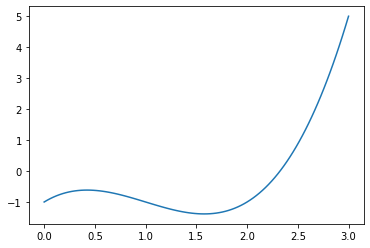

In [65]:
f2 = lambda x: x**3-3*x**2+2*x-1

xplot = np.linspace(0,3,100)
plt.plot(xplot,f2(xplot))

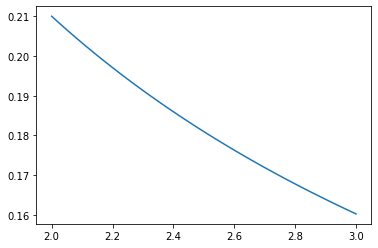

In [71]:
g1 = lambda x: -x**3+3*x**2+1
g2 = lambda x: 1+ (x)**(1/3)

dg1 = lambda x: -3*x**2 + 6*x
dg2 = lambda x: (1/3)*(1/x**(2/3))
y = np.linspace(2,3,100)
#plt.plot(y, dg1(y))
plt.plot(y, dg2(y))

In [74]:
A = np.array([[1/3,2/3,2,3],[1,0,-1,2],[0,0,-5/3,-2/3],[0,0,1,0]])
np.linalg.eig(A)

(array([ 1.        , -0.66666667, -1.        , -0.66666667]),
 array([[ 7.07106781e-01, -5.54700196e-01,  3.03045763e-01,
          5.54700196e-01],
        [ 7.07106781e-01,  8.32050294e-01, -9.09137290e-01,
         -8.32050294e-01],
        [ 0.00000000e+00,  0.00000000e+00, -2.02030509e-01,
          3.07920465e-16],
        [ 0.00000000e+00,  0.00000000e+00,  2.02030509e-01,
         -4.61880697e-16]]))

In [79]:
print(A)
A*A*A*A*A*A*A

[[ 0.33333333  0.66666667  2.          3.        ]
 [ 1.          0.         -1.          2.        ]
 [ 0.          0.         -1.66666667 -0.66666667]
 [ 0.          0.          1.          0.        ]]


array([[ 4.57247371e-04,  5.85276635e-02,  1.28000000e+02,
         2.18700000e+03],
       [ 1.00000000e+00,  0.00000000e+00, -1.00000000e+00,
         1.28000000e+02],
       [ 0.00000000e+00,  0.00000000e+00, -3.57224508e+01,
        -5.85276635e-02],
       [ 0.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         0.00000000e+00]])

In [88]:
B = np.array([[2,1,0],[1,3,1],[0,1,4]])
np.linalg.eig(B)

(array([1.26794919, 3.        , 4.73205081]),
 array([[-0.78867513, -0.57735027,  0.21132487],
        [ 0.57735027, -0.57735027,  0.57735027],
        [-0.21132487,  0.57735027,  0.78867513]]))

In [89]:
v = (1,1,1)/np.sqrt(3)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)
w = B@v
v = w/np.linalg.norm(w)
lam = v@B@v
print(lam)

4.627118644067798
4.694117647058825
4.71702331523475
4.726009720848207
4.729619855518535
4.731073085860341


In [100]:
C = np.array([[8,0,1],[0,8,1],[1,1,7]])
print(C)
d, X = np.linalg.eig(C)

[[8 0 1]
 [0 8 1]
 [1 1 7]]


In [103]:
print(d)
X

[6. 8. 9.]


array([[ 4.08248290e-01, -7.07106781e-01, -5.77350269e-01],
       [ 4.08248290e-01,  7.07106781e-01, -5.77350269e-01],
       [-8.16496581e-01,  1.13147888e-15, -5.77350269e-01]])

In [113]:
def power_iter(A, x):
    v = x.copy()
    for j in range(20):
        w = A@v
        v = w/np.linalg.norm(w)
        lam = v@A@v
        print(lam)
    return lam

In [116]:
power_iter(C, [1/np.sqrt(2),1/np.sqrt(2),0])

8.454545454545457
8.730337078651688
8.873850197109068
8.942592315742267
8.97421131277178
8.988483361418883
8.994870554339546
8.997718078782226
8.998985384037711
8.999548974828366
8.999799527624074
8.99991089785838
8.999960398394727
8.999982399157467
8.99999217737782
8.999996523273994
8.999998454787448
8.99999931323867
8.999999694772699
8.999999864343415


8.999999864343415

In [127]:
#deflste
v = [1,1,1]/np.sqrt(3)
print(C.dot(v)-9*v)
B = C-9*np.outer(v,v)
print(B, 9*np.outer(v,v))
np.linalg.eig(B)

[ 0.0000000e+00  0.0000000e+00 -8.8817842e-16]
[[ 5. -3. -2.]
 [-3.  5. -2.]
 [-2. -2.  4.]] [[3. 3. 3.]
 [3. 3. 3.]
 [3. 3. 3.]]


(array([-1.77635684e-15,  8.00000000e+00,  6.00000000e+00]),
 array([[ 5.77350269e-01,  7.07106781e-01, -4.08248290e-01],
        [ 5.77350269e-01, -7.07106781e-01, -4.08248290e-01],
        [ 5.77350269e-01, -6.82918131e-17,  8.16496581e-01]]))

In [140]:
# Gauss Seidel
n = 10
A = np.array([[1,2],[2,4+1/n**2]])
print(np.linalg.det(A))
print(np.linalg.cond(A))
b = np.array([1, 2-1/n**2])

D = np.array([[1,0],[0,4+1/n**2]])
L = np.array([[0,0],[2,0]])
U = np.array([[0,2],[0,0]])

x0 = [-1,1]
x1 = -np.linalg.inv(D+L)@U@x0 + np.linalg.inv(D+L)@b
print(x1)
x2 = -np.linalg.inv(D+L)@U@x1 + np.linalg.inv(D+L)@b
x3 = -np.linalg.inv(D+L)@U@x2 + np.linalg.inv(D+L)@b
x4 = -np.linalg.inv(D+L)@U@x3 + np.linalg.inv(D+L)@b
x5 = -np.linalg.inv(D+L)@U@x4 + np.linalg.inv(D+L)@b
x6 = -np.linalg.inv(D+L)@U@x5 + np.linalg.inv(D+L)@b
print(x2,x3,x4,x5,x6)

0.009999999999999792
2508.009601277231
[-1.          0.99501247]
[-0.99002494  0.99003738] [-0.98007475  0.98507469] [-0.97014938  0.98012438] [-0.96024876  0.97518641] [-0.95037282  0.97026076]
